# 05 — Um dataset astronômico multimodal

Workshop SAB — AI-Scope / ADSS

**Objetivo:** reunir, para as mesmas fontes, Gaia (astrometria e fotometria), DESI (espectroscopia), ZTF DR22 (séries temporais) e cutouts S-PLUS (imagens). No fim teremos uma tabela com **uma linha por fonte**, além de arquivos com as curvas de luz e imagens. Veremos também onde faltam modalidades — uma situação normal em dados astronômicos.

## 1. Preparação

Execute este notebook a partir da pasta `notebooks/`. A amostra terá até **1.000 fontes Gaia** em um polígono centrado em **RA 0°, Dec 0°**: RA de 358° a 2° e Dec de −1° a +1°. Ajuste `MAX_OBJECTS` para o tempo disponível. Para manter a aula ágil, só baixamos 12 imagens, mas consultamos catálogos e ZTF para toda a amostra.

Credenciais são lidas do ambiente e não são salvas. As consultas dependem da cobertura atual do AI-Scope.

In [56]:
import json
import os
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import adss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

OUT = Path("outputs/multimodal")
OUT.mkdir(parents=True, exist_ok=True)
MATCH_RADIUS_ARCSEC = 1.0
MAX_OBJECTS = 1000
STAMP_PIXELS = 64
MAX_CUTOUTS = 120

## 2. Escolher uma imagem S-PLUS dentro do polígono

O polígono cruza RA 0°. Procuramos, pela API de imagens, um arquivo científico `R` cujo centro esteja dentro dele. A lista pode conter mapas de peso, que não servem para os cutouts. A consulta Gaia na próxima etapa usa o polígono; a imagem escolhida serve para ordenar os objetos mais próximos de uma área com pixels.

In [57]:
collections = pd.DataFrame(cl.get_collections())
if collections.empty:
    raise RuntimeError("Nenhuma coleção de imagens disponível.")
display(collections[[x for x in ["id", "name", "description"] if x in collections]])

preferred = collections[collections["name"].str.contains("splus", case=False, na=False)]
collection = preferred.iloc[0] if not preferred.empty else collections.iloc[0]
COLLECTION_ID = int(collection["id"])

# Polígono de 4° × 2° centrado em (RA, Dec) = (0°, 0°).
POLYGON_RA_WEST, POLYGON_RA_EAST = 358.0, 2.0
POLYGON_DEC_SOUTH, POLYGON_DEC_NORTH = -1.0, 1.0

def inside_polygon_bounds(ra, dec):
    signed_ra = (float(ra) + 180.0) % 360.0 - 180.0
    return -2.0 <= signed_ra <= 2.0 and POLYGON_DEC_SOUTH <= float(dec) <= POLYGON_DEC_NORTH

candidates = cl.cone_search_images(
    collection_id=COLLECTION_ID, ra=0.0, dec=0.0,
    radius=2.5, filter_name="R", limit=100,
)
science_files = [item for item in candidates
                 if (str(item.get("filter", "")).upper() == "R"
                     and "swpweight" not in str(item.get("filename", "")).lower()
                     and pd.notna(item.get("ra_center"))
                     and pd.notna(item.get("dec_center"))
                     and inside_polygon_bounds(item["ra_center"], item["dec_center"]))]
if not science_files:
    raise RuntimeError("Nenhum arquivo R científico encontrado dentro do polígono; revise a coleção/cobertura.")
image_file = min(science_files, key=lambda item: abs((float(item["ra_center"]) + 180) % 360 - 180)
                 + abs(float(item["dec_center"])))
RA0, DEC0 = float(image_file["ra_center"]), float(image_file["dec_center"])
print({k: image_file.get(k) for k in ["id", "object_name", "filter", "ra_center", "dec_center", "pixel_scale"]})

,id,name,description
0,4,splus dr1-dr4,
1,3,splus idr6,splus idr6 collection


{'id': 155856, 'object_name': 'STRIPE82_0001', 'filter': 'R', 'ra_center': 359.99992360541097, 'dec_center': -0.699923611110481, 'pixel_scale': 0.55000000000008}


In [58]:
# Confirme as tabelas e campos essenciais na instância usada durante a aula.
metadata = cl.get_database_metadata()
tables = {f"{schema.name}.{table.name}": {col.name for col in table.columns}
          for schema in metadata.schemas for table in schema.tables}
required = {
    "public.gaia_dr3": {"source_id", "ra", "dec", "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag", "parallax", "pmra", "pmdec", "ruwe"},
    "desi.desi_specz_dr1": {"id", "ra", "dec", "z", "zwarn", "spectype", "deltachi2"},
    "public.ztf_dr22": {"id", "ra", "dec", "filterid", "nepochs", "hmjd", "mag", "magerr"},
}
for table, columns in required.items():
    missing = columns - tables.get(table, set())
    if missing:
        raise RuntimeError(f"Esquema inesperado em {table}: faltam {sorted(missing)}")
print("Tabelas e colunas essenciais confirmadas.")

Tabelas e colunas essenciais confirmadas.


## 3. Gaia: a lista principal de objetos

A consulta usa `polygon(ra, dec, ...)` do AstroQL. Os vértices vão de RA 358° a 2°, atravessando o meridiano 0°, e de Dec −1° a +1°. Ordenamos pela distância ao centro da imagem S-PLUS escolhida; assim os primeiros alvos têm maior chance de produzir cutouts. `TOP` limita a aula, mas essa seleção por proximidade **não é uma amostra representativa** do polígono.

In [59]:
gaia_query = f"""
SELECT TOP {MAX_OBJECTS}
    source_id, ra, dec, phot_g_mean_mag, phot_bp_mean_mag, phot_rp_mean_mag,
    parallax, parallax_error, pmra, pmdec, ruwe,
    dist(ra, dec, {RA0}, {DEC0}) AS image_distance_deg
FROM public.gaia_dr3
WHERE polygon(
    ra, dec,
    {POLYGON_RA_WEST}, {POLYGON_DEC_SOUTH},
    {POLYGON_RA_EAST}, {POLYGON_DEC_SOUTH},
    {POLYGON_RA_EAST}, {POLYGON_DEC_NORTH},
    {POLYGON_RA_WEST}, {POLYGON_DEC_NORTH}
)
  AND phot_g_mean_mag IS NOT NULL
ORDER BY image_distance_deg
"""
gaia = cl.query_and_wait(query_text=gaia_query, mode="astroql", verbose=0).data.copy()
if gaia.empty:
    raise RuntimeError("Nenhuma fonte Gaia no polígono; confira coordenadas e cobertura da tabela.")
gaia["object_id"] = "gaia_" + gaia["source_id"].astype(str)
if not gaia.object_id.is_unique:
    raise RuntimeError("A consulta Gaia retornou IDs repetidos.")
objects = gaia[["object_id", "ra", "dec"]].copy()
print(f"Fontes Gaia: {len(objects)}")
display(gaia.head())

Fontes Gaia: 1000


,source_id,ra,dec,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,parallax,parallax_error,pmra,pmdec,ruwe,image_distance_deg,object_id
0,2449850960546191232,0.009517,-0.680439,19.797432,21.076393,18.537184,1.768937,0.538362,3.027674,-8.816400,1.087202,0.021718,gaia_2449850960546191232
1,2449850479509840896,0.007879,-0.724539,18.737270,19.668087,17.806042,0.538293,0.242018,11.237408,-3.181053,1.044982,0.025869,gaia_2449850479509840896
2,2449850689964579584,0.025747,-0.702557,15.303093,16.247883,14.340668,5.013227,0.043259,-71.261257,-57.685904,1.073296,0.025955,gaia_2449850689964579584
3,2449851338503315712,0.006008,-0.673501,18.063745,19.144247,16.583400,NaN,NaN,NaN,NaN,NaN,0.027114,gaia_2449851338503315712
4,2449851269783834624,0.023429,-0.685347,20.674437,21.188625,19.480910,2.443013,1.681804,9.057399,0.191879,0.983312,0.027657,gaia_2449851269783834624


## 4. DESI: espectroscopia por posição

Enviamos as coordenadas Gaia como tabela temporária e buscamos pares a até 1 arcsec. Se houver vários candidatos, guardamos o mais próximo e registramos quantos havia. Mesmo uma associação próxima pode ser incorreta; a flag de qualidade também exige `zwarn = 0`.

In [60]:
desi_query = f"""
SELECT
    u.object_id, d.id AS desi_id, d.ra AS desi_ra, d.dec AS desi_dec,
    d.z, d.zerr, d.zwarn, d.spectype, d.subtype, d.deltachi2,
    dist(u.ra, u.dec, d.ra, d.dec) AS desi_sep_deg
FROM upload.objects AS u
JOIN desi.desi_specz_dr1 AS d
  ON cone(d.ra, d.dec, u.ra, u.dec, {MATCH_RADIUS_ARCSEC / 3600.0})
"""
raw_desi = cl.query_and_wait(
    query_text=desi_query, mode="astroql", file=objects,
    table_name="objects", verbose=0,
).data.copy()

expected = ["object_id", "desi_id", "desi_ra", "desi_dec", "z", "zerr", "zwarn",
            "spectype", "subtype", "deltachi2", "desi_sep_deg"]
if raw_desi.empty:
    raw_desi = pd.DataFrame(columns=expected)
raw_desi["desi_id"] = raw_desi["desi_id"].astype("string")
raw_desi["desi_sep_arcsec"] = pd.to_numeric(raw_desi["desi_sep_deg"], errors="coerce") * 3600
candidate_counts = raw_desi.groupby("object_id").size().rename("n_desi_candidates")
desi_best = (raw_desi.sort_values(["object_id", "desi_sep_arcsec", "desi_id"])
             .drop_duplicates("object_id")
             .merge(candidate_counts, on="object_id", validate="one_to_one"))
print(f"Associações DESI: {len(raw_desi)}; objetos com candidato: {len(desi_best)}; "
      f"objetos ambíguos: {(candidate_counts > 1).sum()}")
display(desi_best.head())

Associações DESI: 136; objetos com candidato: 126; objetos ambíguos: 9


,object_id,desi_id,desi_ra,desi_dec,z,zerr,zwarn,spectype,subtype,deltachi2,desi_sep_deg,desi_sep_arcsec,n_desi_candidates
0,gaia_2449821690344555904,39627760569682030,0.066050,-0.994903,0.978644,0.000298,0,QSO,LOZ,131.545829,6.884636e-07,0.002478,1
1,gaia_2449823992447846912,39627766605287883,359.904079,-0.990560,-0.000397,0.000005,0,STAR,K,3938.136340,2.156090e-06,0.007762,1
2,gaia_2449825465620661888,39627766605288996,359.939569,-0.972141,1.819592,0.000162,0,QSO,HIZ,24821.761316,6.394942e-08,0.000230,1
3,gaia_2449825534340140416,39627766605288801,359.933902,-0.960630,1.790332,0.000255,0,QSO,HIZ,9545.533826,9.178932e-08,0.000330,1
4,gaia_2449825744794530432,39627760569679946,0.002284,-0.950079,-0.000505,0.000003,0,STAR,G,39570.731976,1.767596e-06,0.006363,1


## 5. ZTF DR22: a dimensão temporal

A tabela ZTF guarda tempos (`hmjd`), magnitudes (`mag`) e erros (`magerr`) em arrays. Buscamos as fontes ZTF próximas dos mesmos objetos Gaia. Se um objeto tiver mais de uma linha (por exemplo, filtros diferentes), usamos a linha mais próxima e, em empate, a mais amostrada. Guardamos o número de candidatos para revisão. Os arrays completos serão exportados separadamente; no manifest entram apenas resumo e referência.

In [61]:
ztf_query = f"""
SELECT
    u.object_id, z.id AS ztf_id, z.ra AS ztf_ra, z.dec AS ztf_dec,
    z.filterid, z.nepochs, z.hmjd, z.mag, z.magerr,
    dist(u.ra, u.dec, z.ra, z.dec) AS ztf_sep_deg
FROM upload.objects AS u
JOIN public.ztf_dr22 AS z
  ON cone(z.ra, z.dec, u.ra, u.dec, {MATCH_RADIUS_ARCSEC / 3600.0})
"""
raw_ztf = cl.query_and_wait(
    query_text=ztf_query, mode="astroql", file=objects,
    table_name="objects", verbose=0,
).data.copy()
expected_ztf = ["object_id", "ztf_id", "ztf_ra", "ztf_dec", "filterid",
                "nepochs", "hmjd", "mag", "magerr", "ztf_sep_deg"]
if raw_ztf.empty:
    raw_ztf = pd.DataFrame(columns=expected_ztf)
raw_ztf["ztf_id"] = raw_ztf["ztf_id"].astype("string")
raw_ztf["ztf_sep_arcsec"] = pd.to_numeric(raw_ztf["ztf_sep_deg"], errors="coerce") * 3600
raw_ztf["nepochs"] = pd.to_numeric(raw_ztf["nepochs"], errors="coerce")
ztf_counts = raw_ztf.groupby("object_id").size().rename("n_ztf_candidates")
ztf_best = (raw_ztf.sort_values(["object_id", "ztf_sep_arcsec", "nepochs"],
                                ascending=[True, True, False])
            .drop_duplicates("object_id")
            .merge(ztf_counts, on="object_id", validate="one_to_one"))
print(f"Linhas ZTF: {len(raw_ztf)}; objetos com ZTF: {len(ztf_best)}; "
      f"objetos com mais de uma linha: {(ztf_counts > 1).sum()}")
display(ztf_best[["object_id", "ztf_id", "filterid", "nepochs",
                  "ztf_sep_arcsec", "n_ztf_candidates"]].head())

Linhas ZTF: 2731; objetos com ZTF: 908; objetos com mais de uma linha: 829


,object_id,ztf_id,filterid,nepochs,ztf_sep_arcsec,n_ztf_candidates
0,gaia_2449821690344555904,396211200009808,2,76,0.092201,3
1,gaia_2449821754768511488,396211200001456,2,331,0.067716,3
2,gaia_2449821789128250752,396211200009739,2,246,0.078404,3
3,gaia_2449821823488806144,396211200001304,2,110,0.070229,2
4,gaia_2449823953792171264,396211200001404,2,38,0.033664,3


### Resumir cada curva de luz

A amplitude entre os percentis 5 e 95 é uma descrição simples da variabilidade. Não é um teste de variabilidade: erros, artefatos, filtro e cadência precisam ser analisados. Exigimos pelo menos cinco medidas finitas com erro positivo.

In [62]:
def curve_summary(row):
    t = np.asarray(row["hmjd"], dtype=float)
    mag = np.asarray(row["mag"], dtype=float)
    err = np.asarray(row["magerr"], dtype=float)
    if not (len(t) == len(mag) == len(err)):
        return pd.Series({"ztf_n_valid": 0, "ztf_median_mag": np.nan, "ztf_amp90": np.nan})
    good = np.isfinite(t) & np.isfinite(mag) & np.isfinite(err) & (err > 0)
    values = mag[good]
    if len(values) < 5:
        return pd.Series({"ztf_n_valid": len(values), "ztf_median_mag": np.nan, "ztf_amp90": np.nan})
    return pd.Series({"ztf_n_valid": len(values),
                      "ztf_median_mag": np.median(values),
                      "ztf_amp90": np.percentile(values, 95) - np.percentile(values, 5)})

ztf_features = (pd.concat([ztf_best.drop(columns=["hmjd", "mag", "magerr"]),
                           ztf_best.apply(curve_summary, axis=1)], axis=1)
                if not ztf_best.empty else
                pd.DataFrame(columns=["object_id", "ztf_id", "filterid", "nepochs",
                                      "ztf_sep_arcsec", "n_ztf_candidates",
                                      "ztf_n_valid", "ztf_median_mag", "ztf_amp90"]))
display(ztf_features[["object_id", "ztf_n_valid", "ztf_median_mag", "ztf_amp90"]].head())

,object_id,ztf_n_valid,ztf_median_mag,ztf_amp90
0,gaia_2449821690344555904,76.0,20.841017,1.194982
1,gaia_2449821754768511488,331.0,19.324398,0.304054
2,gaia_2449821789128250752,246.0,20.131684,0.580654
3,gaia_2449821823488806144,110.0,21.029042,0.753365
4,gaia_2449823953792171264,38.0,19.702396,0.254775


## 6. Juntar tudo: uma linha por fonte Gaia

As associações DESI e ZTF são opcionais. Um campo vazio significa que aquela modalidade não foi encontrada; não representa valor físico zero. Verificamos a unicidade após cada redução de candidatos.

In [63]:
manifest = gaia.merge(desi_best, on="object_id", how="left", validate="one_to_one")
manifest = manifest.merge(ztf_features, on="object_id", how="left", validate="one_to_one")
manifest["n_desi_candidates"] = manifest["n_desi_candidates"].fillna(0).astype(int)
manifest["n_ztf_candidates"] = manifest["n_ztf_candidates"].fillna(0).astype(int)
manifest["has_desi"] = manifest["desi_id"].notna()
manifest["has_ztf"] = manifest["ztf_id"].notna()
manifest["has_good_astrometry"] = pd.to_numeric(manifest["ruwe"], errors="coerce").lt(1.4) & manifest["parallax"].notna()
manifest["has_secure_desi_z"] = (manifest["has_desi"]
                                  & pd.to_numeric(manifest["zwarn"], errors="coerce").eq(0)
                                  & manifest["z"].notna()
                                  & manifest["n_desi_candidates"].eq(1))
manifest["bp_minus_rp"] = manifest["phot_bp_mean_mag"] - manifest["phot_rp_mean_mag"]
manifest["image_collection_id"] = COLLECTION_ID
manifest["image_file_id"] = int(image_file["id"])
manifest["image_filter"] = str(image_file["filter"])
manifest["stamp_size_px"] = STAMP_PIXELS
manifest["stamp_path"] = pd.NA
manifest["stamp_status"] = "not_requested"
assert len(manifest) == len(objects) and manifest.object_id.is_unique
print(f"Manifest: {len(manifest)} objetos, {manifest.has_desi.sum()} com DESI, {manifest.has_ztf.sum()} com ZTF")
display(manifest[["object_id", "phot_g_mean_mag", "bp_minus_rp", "desi_id",
                  "ztf_id", "ztf_n_valid", "ztf_amp90"]].head(10))

Manifest: 1000 objetos, 126 com DESI, 908 com ZTF


,object_id,phot_g_mean_mag,bp_minus_rp,desi_id,ztf_id,ztf_n_valid,ztf_amp90
0,gaia_2449850960546191232,19.797432,2.539209,<NA>,1492206400014544,44.0,0.510444
1,gaia_2449850479509840896,18.737270,1.862045,<NA>,1492206400006980,51.0,0.121466
2,gaia_2449850689964579584,15.303093,1.907215,<NA>,1492206400006747,54.0,0.057455
3,gaia_2449851338503315712,18.063745,2.560847,<NA>,1492206400006471,54.0,0.105201
4,gaia_2449851269783834624,20.674437,1.707715,<NA>,1492206400014588,26.0,0.611986
5,gaia_2449851716461076736,20.894098,0.298544,<NA>,1492206400006460,37.0,0.532602
6,gaia_2449850685668514304,20.761002,1.619024,<NA>,1492206400006712,26.0,0.603799
7,gaia_2449851716460836608,19.592205,1.933189,<NA>,1492206400014447,50.0,0.285082
8,gaia_2449850445150500224,19.116056,2.749333,<NA>,1492206400007085,49.0,0.258702
9,gaia_2449851067921701504,17.292448,1.861641,<NA>,1492106400004076,48.0,0.206565


## 7. Imagens: poucos exemplos para inspeção

Baixamos 12 cutouts FITS do mesmo arquivo `R`, sempre ligados ao `object_id`. Em uma preparação completa, repita o passo para todos os alvos e escolha uma política para falhas. O status diferencia imagem disponível, não requisitada e falha.

In [64]:
image_dir = OUT / "images"
image_dir.mkdir(exist_ok=True)
for idx, row in manifest.head(MAX_CUTOUTS).iterrows():
    try:
        stamp_bytes = cl.create_stamp(
            file_id=int(image_file["id"]), ra=float(row["ra"]), dec=float(row["dec"]),
            size=STAMP_PIXELS, size_unit="pixels", format="fits",
        )
        with fits.open(BytesIO(stamp_bytes)) as hdul:
            plane = next((hdu.data for hdu in hdul if hdu.data is not None), None)
            if plane is None or not np.isfinite(plane).any():
                raise ValueError("cutout sem pixels finitos")
        path = image_dir / f"{row['object_id']}_R.fits"
        path.write_bytes(stamp_bytes)
        manifest.loc[idx, "stamp_path"] = str(path)
        manifest.loc[idx, "stamp_status"] = "available"
    except Exception as exc:
        manifest.loc[idx, "stamp_status"] = f"failed: {type(exc).__name__}"

print(manifest.stamp_status.value_counts())
display(manifest[["object_id", "stamp_path", "stamp_status"]].head(MAX_CUTOUTS))

stamp_status
not_requested    880
available        120
Name: count, dtype: int64


,object_id,stamp_path,stamp_status
0,gaia_2449850960546191232,outputs/multimodal/images/gaia_244985096054619...,available
1,gaia_2449850479509840896,outputs/multimodal/images/gaia_244985047950984...,available
2,gaia_2449850689964579584,outputs/multimodal/images/gaia_244985068996457...,available
3,gaia_2449851338503315712,outputs/multimodal/images/gaia_244985133850331...,available
4,gaia_2449851269783834624,outputs/multimodal/images/gaia_244985126978383...,available
...,...,...,...
115,gaia_2449876043155232768,outputs/multimodal/images/gaia_244987604315523...,available
116,gaia_2449876047451493376,outputs/multimodal/images/gaia_244987604745149...,available
117,gaia_2449850273353432704,outputs/multimodal/images/gaia_244985027335343...,available
118,gaia_2449876116170969728,outputs/multimodal/images/gaia_244987611617096...,available


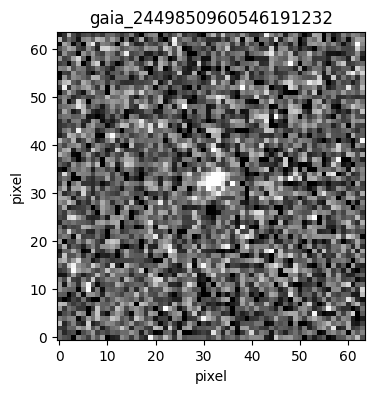

In [65]:
available = manifest[manifest.stamp_status.eq("available")]
if not available.empty:
    with fits.open(available.iloc[0].stamp_path) as hdul:
        image = next(hdu.data for hdu in hdul if hdu.data is not None)
    lo, hi = np.nanpercentile(image, [5, 99.5])
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(image, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set(title=available.iloc[0].object_id, xlabel="pixel", ylabel="pixel")
    plt.show()
else:
    print("Nenhum cutout disponível; revise campo, cobertura e resposta do serviço.")

## 8. Visualizar o dataset

Os gráficos abaixo mostram cobertura das modalidades, distribuição Gaia e alguns resumos de ZTF. Eles ajudam a detectar seleção e dados ausentes antes de qualquer treinamento. Magnitudes menores são mais brilhantes.

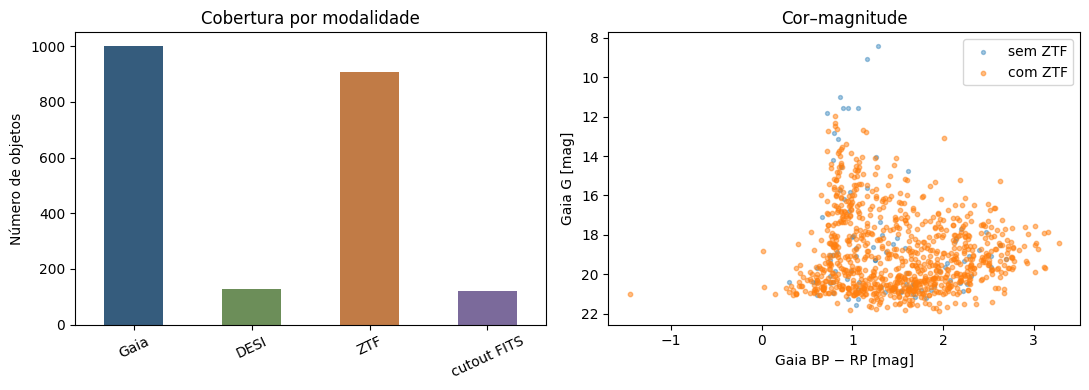

In [66]:
coverage = pd.Series({
    "Gaia": len(manifest),
    "DESI": int(manifest.has_desi.sum()),
    "ZTF": int(manifest.has_ztf.sum()),
    "cutout FITS": int(manifest.stamp_status.eq("available").sum()),
})
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
coverage.plot.bar(ax=axes[0], color=["#355c7d", "#6c8e59", "#c17b46", "#7b6a9b"])
axes[0].set(ylabel="Número de objetos", title="Cobertura por modalidade")
axes[0].tick_params(axis="x", rotation=25)
axes[1].scatter(manifest.loc[~manifest.has_ztf, "bp_minus_rp"],
                manifest.loc[~manifest.has_ztf, "phot_g_mean_mag"],
                s=8, alpha=0.4, label="sem ZTF")
axes[1].scatter(manifest.loc[manifest.has_ztf, "bp_minus_rp"],
                manifest.loc[manifest.has_ztf, "phot_g_mean_mag"],
                s=10, alpha=0.5, label="com ZTF")
axes[1].invert_yaxis()
axes[1].set(xlabel="Gaia BP − RP [mag]", ylabel="Gaia G [mag]", title="Cor–magnitude")
axes[1].legend()
plt.tight_layout()
plt.show()

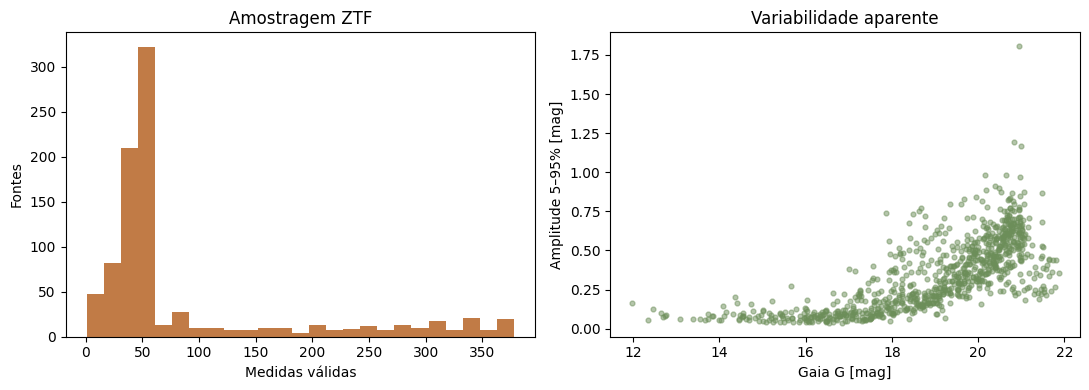

In [67]:
if manifest.has_ztf.any():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ztf_subset = manifest[manifest.has_ztf]
    axes[0].hist(ztf_subset["ztf_n_valid"].dropna(), bins=25, color="#c17b46")
    axes[0].set(xlabel="Medidas válidas", ylabel="Fontes", title="Amostragem ZTF")
    axes[1].scatter(ztf_subset["phot_g_mean_mag"], ztf_subset["ztf_amp90"],
                    s=12, alpha=0.5, color="#6c8e59")
    axes[1].set(xlabel="Gaia G [mag]", ylabel="Amplitude 5–95% [mag]",
                title="Variabilidade aparente")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma associação ZTF neste campo; escolha outro campo para ver estes gráficos.")

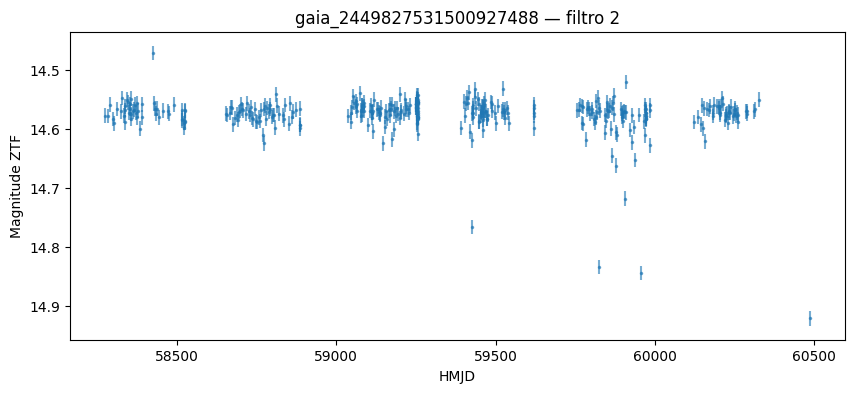

In [68]:
if not ztf_best.empty:
    row = ztf_best.sort_values("nepochs", ascending=False).iloc[0]
    t = np.asarray(row["hmjd"], dtype=float)
    mag = np.asarray(row["mag"], dtype=float)
    err = np.asarray(row["magerr"], dtype=float)
    good = np.isfinite(t) & np.isfinite(mag) & np.isfinite(err) & (err > 0)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.errorbar(t[good], mag[good], yerr=err[good], fmt=".", ms=3, alpha=0.6)
    ax.invert_yaxis()
    ax.set(xlabel="HMJD", ylabel="Magnitude ZTF", title=f"{row['object_id']} — filtro {row['filterid']}")
    plt.show()

## 9. Salvar e conferir

O CSV guarda uma linha por objeto e o caminho dos cutouts. O JSONL guarda os arrays ZTF, um registro por `object_id` com curva disponível. Assim o manifest continua leve. O arquivo de proveniência registra consultas, parâmetros e data; ele não contém credenciais.

In [69]:
summary = pd.DataFrame({
    "metric": ["objects", "with_desi", "with_ztf", "secure_desi_z",
               "good_astrometry", "ambiguous_desi", "multiple_ztf_rows", "stamps_available"],
    "count": [len(manifest), int(manifest.has_desi.sum()), int(manifest.has_ztf.sum()),
              int(manifest.has_secure_desi_z.sum()), int(manifest.has_good_astrometry.sum()),
              int(manifest.n_desi_candidates.gt(1).sum()),
              int(manifest.n_ztf_candidates.gt(1).sum()),
              int(manifest.stamp_status.eq("available").sum())],
})
display(summary)

# Os arrays ficam em arquivo separado para não transformar cada célula CSV em uma lista longa.
def json_array(values):
    array = np.asarray(values, dtype=float)
    return [float(x) if np.isfinite(x) else None for x in array]

curves_path = OUT / "ztf_lightcurves.jsonl"
with curves_path.open("w", encoding="utf-8") as handle:
    for _, row in ztf_best.iterrows():
        record = {"object_id": row["object_id"], "ztf_id": str(row["ztf_id"]),
                  "filterid": None if pd.isna(row["filterid"]) else int(row["filterid"]),
                  "hmjd": json_array(row["hmjd"]),
                  "mag": json_array(row["mag"]),
                  "magerr": json_array(row["magerr"])}
        handle.write(json.dumps(record, allow_nan=False) + "\n")
manifest["ztf_curve_file"] = np.where(manifest.has_ztf, str(curves_path), "")
manifest_path = OUT / "manifest.csv"
manifest.to_csv(manifest_path, index=False)
provenance = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "base_url": BASE_URL,
    "adss_version": getattr(adss, "__version__", "unknown"),
    "gaia_query": gaia_query,
    "desi_query": desi_query,
    "ztf_query": ztf_query,
    "collection_id": COLLECTION_ID,
    "image_file_id": int(image_file["id"]),
    "image_filename": image_file["filename"],
    "match_radius_arcsec": MATCH_RADIUS_ARCSEC,
    "polygon_vertices_ra_dec_deg": [[POLYGON_RA_WEST, POLYGON_DEC_SOUTH],
                                   [POLYGON_RA_EAST, POLYGON_DEC_SOUTH],
                                   [POLYGON_RA_EAST, POLYGON_DEC_NORTH],
                                   [POLYGON_RA_WEST, POLYGON_DEC_NORTH]],
    "max_objects": MAX_OBJECTS,
    "stamp_size_px": STAMP_PIXELS,
    "max_cutouts": MAX_CUTOUTS,
    "match_rule": "nearest angular separation; DESI ties by ID; ZTF ties by number of epochs",
}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2, ensure_ascii=False))
print("Salvos:", manifest_path, curves_path, OUT / "provenance.json")

,metric,count
0,objects,1000
1,with_desi,126
2,with_ztf,908
3,secure_desi_z,117
4,good_astrometry,800
5,ambiguous_desi,9
6,multiple_ztf_rows,829
7,stamps_available,120


Salvos: outputs/multimodal/manifest.csv outputs/multimodal/ztf_lightcurves.jsonl outputs/multimodal/provenance.json


## Exercícios

1. Compare a magnitude G de fontes com e sem ZTF. A ausência de ZTF parece aleatória?
2. Inspecione fontes com `n_desi_candidates > 1` ou `n_ztf_candidates > 1`. Mude o raio de associação para 0,5 arcsec: quantas associações permanecem?
3. Escolha três curvas de luz com maior `ztf_amp90`. Todas parecem variáveis reais? Examine erros e pontos isolados.
4. Para um dataset de treino maior, aumente `MAX_OBJECTS` e baixe cutouts em lotes. Separe treino/teste por região do céu ou campo de imagem para reduzir vazamento. Registre a seleção e a versão dos dados.